# Roman WFI F158: fitting a simulated galaxy

This notebook fits a single-Sérsic model to a simulated Roman WFI F158 image with BayMorph's production forward model, noise model and sampler.
The image is idealised: every pixel is synthetic, and the PSF is a two-Gaussian stand-in for the Roman PSF.

In [1]:
import time
import warnings

import numpy as np
from astropy.table import Table
from scipy.integrate import IntegrationWarning
from scipy.special import ndtr

import baymorph
from baymorph import EmpiricalPSF
from baymorph.fitting import (
    LogUniformPrior,
    ObservedModelFactory,
    Parameter,
    ParameterSet,
    UniformPrior,
    make_sampler,
)
from baymorph.fitting.image_problem import ImageInferenceProblem
from baymorph.likelihood.vecchia_gaussian import (
    VecchiaCorrelatedGaussianImageLikelihood,
    build_vecchia_factorization,
)
from baymorph.models import get_model
from baymorph.observation.background import background_parameter_names
from baymorph.plotting import plot_log_data_model_residual
from baymorph.stats.weighted import posterior_summary

## Observation

WFI F158 at 0.11 arcsec per pixel: six exposures of 107.524 s, as in the Medium tier of the High Latitude Wide Area Survey (3 dithers × 2 passes), summed in electrons.
The background noise is 23.6 e- per pixel; the source adds its own photon noise.

In [2]:
PIXEL_SCALE = 0.11  # arcsec/px
SHAPE = (201, 201)  # px
TARGET_X, TARGET_Y = 100, 100  # px, 0-based, pixel centres at integers
ZP = 26.32251053616207  # AB mag for 1 e-/s (Roman zeropoints of 2024-03-01, WFI01)
EXPOSURE = 6 * 107.524  # s
ZP_IMG = ZP + 2.5 * np.log10(EXPOSURE)  # AB mag for 1 e- in the summed image
SKY_VARIANCE = 559.0  # e-^2 per pixel
SKY_SIGMA = np.sqrt(SKY_VARIANCE)  # e-
GAIN = 1.0  # e- per image unit

## Effective PSF

A core Gaussian of FWHM 0.128 arcsec (62 % of the light) plus a halo Gaussian of sigma 0.44 arcsec = 4 px (38 %).
The core FWHM is 1.16 px, so the PSF is undersampled: BayMorph renders the galaxy with the PSF integrated over the pixel and tabulated at 11 × 11 sub-pixel phases, instead of sampling the profile at pixel centres.

In [3]:
def effective_psf(weights, sigmas, size=51, factor=11):
    """Return a sum of circular Gaussians convolved with the unit pixel.

    Kernel [j, i] is the phase ((i - c) / f, (j - c) / f), c = (f - 1) // 2;
    its pixel [b, a] is the effective PSF at offset (a - h, b - h) plus the
    phase, h = size // 2. Each phase is normalised to unit sum.
    """

    def pixel_response(offsets, sigma):
        # exact Gaussian integral over one pixel, taken in the lower tail
        tail = -np.abs(offsets)
        return ndtr((tail + 0.5) / sigma) - ndtr((tail - 0.5) / sigma)

    offsets = np.arange(size) - size // 2  # px
    phases = (np.arange(factor) - (factor - 1) // 2) / factor  # px
    kernels = np.zeros((factor, factor, size, size))

    for j, phase_y in enumerate(phases):
        for i, phase_x in enumerate(phases):
            for weight, sigma in zip(weights, sigmas, strict=True):
                kernels[j, i] += weight * np.outer(
                    pixel_response(offsets + phase_y, sigma),
                    pixel_response(offsets + phase_x, sigma),
                )
            kernels[j, i] /= kernels[j, i].sum()

    centre = (factor - 1) // 2
    return EmpiricalPSF(
        kernel_array=kernels[centre, centre].copy(), subpixel_kernels=kernels
    )


CORE_FWHM = 0.128 / PIXEL_SCALE  # px
core_sigma = CORE_FWHM / (2.0 * np.sqrt(2.0 * np.log(2.0)))  # px
psf = effective_psf(weights=(0.62, 0.38), sigmas=(core_sigma, 4.0))
assert psf.has_subpixel_kernels

## Simulated image

The image comes from the same forward model the fit uses, so this notebook shows the workflow, not a validation.
The sky is taken as subtracted; a residual constant background is still fitted (truth 0).

In [4]:
H_TRUE = 21.0  # AB mag
RE_TRUE = 0.43  # arcsec
truth = {
    "flux": 10 ** (0.4 * (ZP_IMG - H_TRUE)),  # e-
    "re": RE_TRUE / PIXEL_SCALE,  # px
    "n": 4.0,
    "q": 0.7,
    "theta": np.radians(30.0),  # rad, major axis from +x towards +y
    "x0": 100.31,  # px, column
    "y0": 99.83,  # px, row
}
factory = ObservedModelFactory(
    "single_sersic", background_model="constant", psf=psf
)
source_true = factory(**truth, background_level=0.0).render_prediction(SHAPE)[1]

# Gaussian noise of variance sky plus source counts, in e-
z = np.random.default_rng(20261028).standard_normal(SHAPE)
data = source_true + z * np.sqrt(SKY_VARIANCE + np.maximum(source_true, 0) / GAIN)
assert np.all(np.isfinite(data))

## Priors and likelihood

Broad default priors, not centred on the truth; the centre prior extends 3 core FWHM on either side of the target pixel (100, 100).
The likelihood is BayMorph's Gaussian noise model, with sky plus source variance and uncorrelated noise.

In [5]:
priors = {
    "flux": LogUniformPrior(  # e-, H_AB from 30 to 8 mag
        lower=10 ** (0.4 * (ZP_IMG - 30.0)), upper=10 ** (0.4 * (ZP_IMG - 8.0))
    ),
    "re": LogUniformPrior(  # px, 0.1 to 120 arcsec and at least 1 px
        lower=max(0.1 / PIXEL_SCALE, 1.0), upper=120.0 / PIXEL_SCALE
    ),
    "n": UniformPrior(lower=0.5, upper=6.0),
    "q": UniformPrior(lower=0.2, upper=1.0),
    "theta": UniformPrior(lower=-np.pi / 2, upper=np.pi / 2),  # rad
    "x0": UniformPrior(lower=TARGET_X - 3 * CORE_FWHM, upper=TARGET_X + 3 * CORE_FWHM),
    "y0": UniformPrior(lower=TARGET_Y - 3 * CORE_FWHM, upper=TARGET_Y + 3 * CORE_FWHM),
    "background_level": UniformPrior(lower=-5 * SKY_SIGMA, upper=5 * SKY_SIGMA),  # e-
}
names = [
    *get_model("single_sersic").parameter_names,
    *background_parameter_names("constant"),
]
assert names == list(priors) == list(factory.parameter_names)
parameters = ParameterSet([Parameter(name, prior=priors[name]) for name in names])

# Marginal variance SKY_VARIANCE + max(source, 0) / GAIN, no correlation
mask = np.zeros(SHAPE, dtype=bool)  # True would exclude a pixel
correlation = np.ones((1, 1))
likelihood = VecchiaCorrelatedGaussianImageLikelihood(
    data,
    noise=SKY_SIGMA,
    correlation_kernel=correlation,
    mask=mask,
    factorization=build_vecchia_factorization(mask, correlation, max_neighbors=24),
    max_neighbors=24,
    include_normalization=True,
    effective_gain=GAIN,
)
problem = ImageInferenceProblem(
    model_factory=factory, parameters=parameters, likelihood=likelihood
)

## Fit

Settings: Nautilus with 1000 live points and 4000 effective samples, seed 42, on 4 processes; no progress output and no checkpoint file.

In [6]:
sampler_cfg = {
    "name": "nautilus",
    "init": {"n_live": 1000, "seed": 42},
    "run": {"n_eff": 4000},
    "execution": {"processes": 4, "progress": False},
}
backend = make_sampler(sampler_cfg, problem=problem)

# SciPy's quad in the central-pixel integral can warn at rare points of the
# exploration phase, which Nautilus discards from the posterior
warnings.filterwarnings(
    "ignore",
    category=IntegrationWarning,
    module=r"baymorph\.rendering\.sersic_hybrid",
)
start = time.perf_counter()
result = backend.fit()
wall_time = time.perf_counter() - start  # s

## Data, model and residuals

The central 51 × 51 px (5.6 arcsec) of the stamp; the fit uses all 201 × 201 px.
The model is rendered at the maximum-likelihood sample, and the last panel is the residual standardised by the noise model.

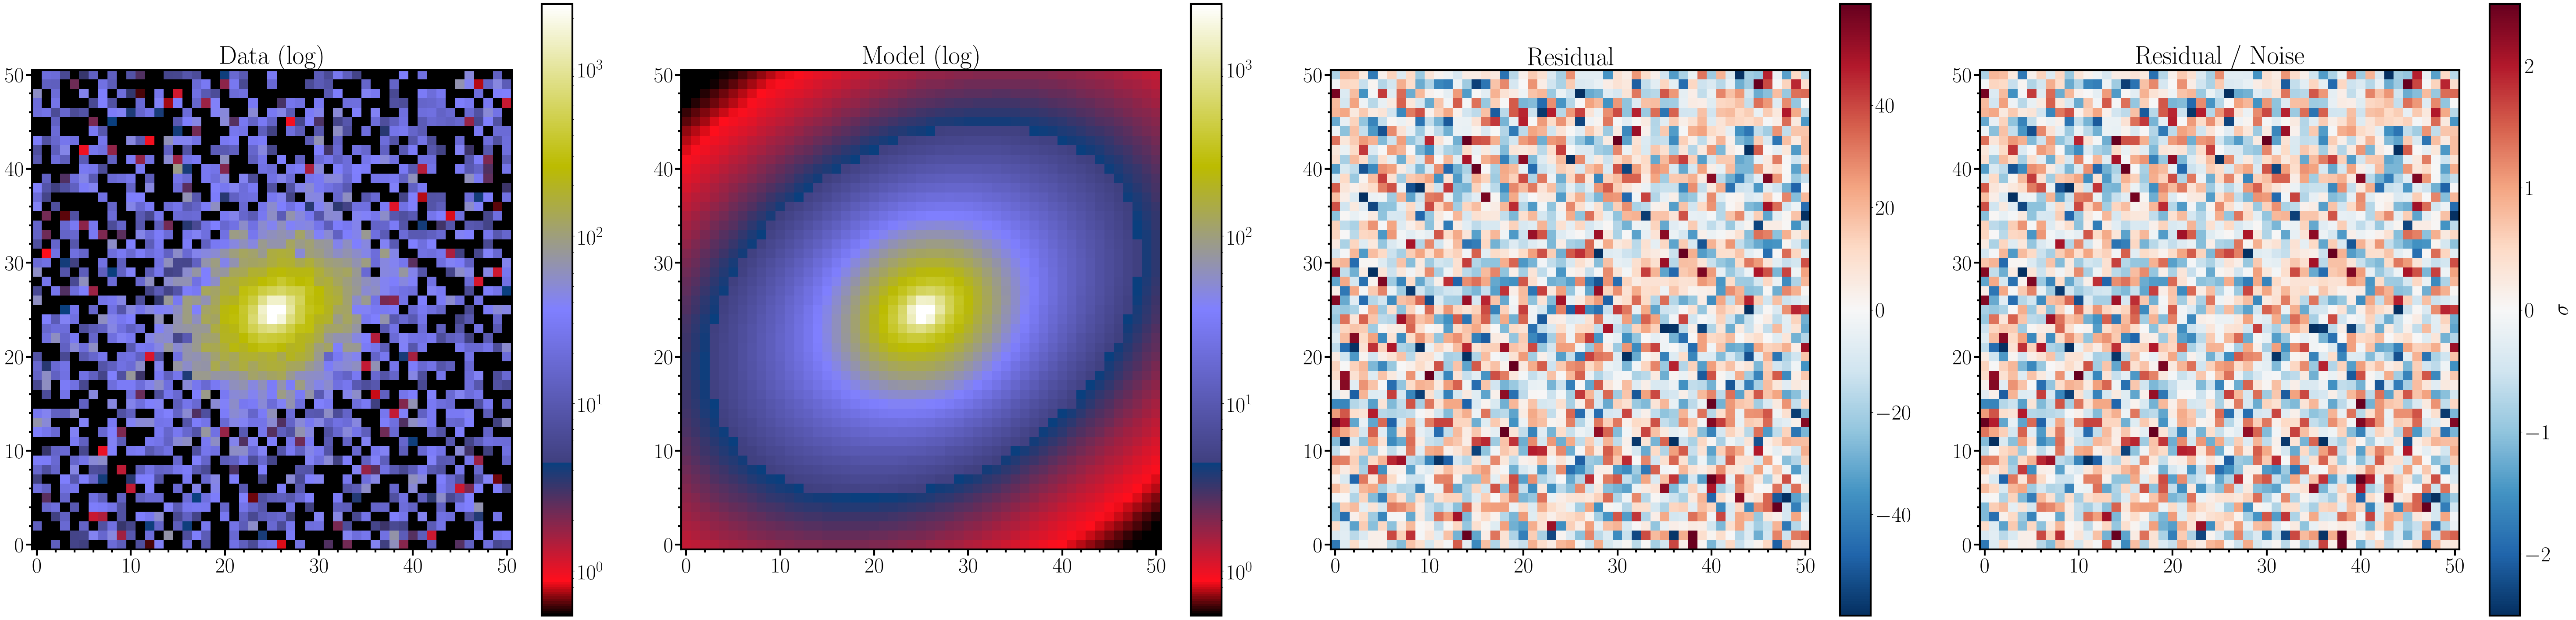

In [7]:
best = {name: result.best_parameters[name] for name in names}
model, source = factory(**best).render_prediction(SHAPE)
norm_residual = likelihood.marginal_standardized_residual(model, source)
half = 25  # px: the central 51 x 51 px, 5.6 arcsec
zoom = np.s_[
    TARGET_Y - half : TARGET_Y + half + 1, TARGET_X - half : TARGET_X + half + 1
]
fig, axes = plot_log_data_model_residual(
    data[zoom], model[zoom], norm_residual=norm_residual[zoom], title="", show=True
)

## Parameters

Weighted posterior medians and 68 % half-widths, 0.5 (q84 - q16), against the truth.

In [8]:
values = dict(zip(result.parameter_names, result.samples.T, strict=True))
derived = {  # user units, computed sample by sample
    "H_AB (mag)": (ZP_IMG - 2.5 * np.log10(values["flux"]), H_TRUE),
    "R_e (arcsec)": (values["re"] * PIXEL_SCALE, RE_TRUE),
    "n": (values["n"], truth["n"]),
    "q": (values["q"], truth["q"]),
    "theta (deg)": (np.degrees(values["theta"]), np.degrees(truth["theta"])),
    "x0 (px)": (values["x0"], truth["x0"]),
    "y0 (px)": (values["y0"], truth["y0"]),
    "background (e-)": (values["background_level"], 0.0),
}
summaries, records = {}, []
for label, (samples, true_value) in derived.items():
    quantiles = posterior_summary(samples, result.weights)
    half_width = 0.5 * (quantiles["q84"] - quantiles["q16"])
    offset = (quantiles["median"] - true_value) / half_width
    summaries[label] = quantiles
    # truth, median and half-width to two significant digits of the half-width
    decimals = max(0, 1 - int(np.floor(np.log10(half_width))))
    strings = [
        f"{value:.{decimals}f}"
        for value in (true_value, quantiles["median"], half_width)
    ]
    records.append((label, *strings, offset))

# H_AB decreases with the flux, so its 16th and 84th percentiles swap
flux = result.summary("flux")
h_from_flux = ZP_IMG - 2.5 * np.log10([flux["q84"], flux["median"], flux["q16"]])
h_quantiles = [summaries["H_AB (mag)"][key] for key in ("q16", "median", "q84")]
assert np.allclose(h_quantiles, h_from_flux, rtol=0.0, atol=1e-4)

table = Table(
    rows=records,
    names=("parameter", "truth", "median", "half-width", "offset / half-width"),
)
table["offset / half-width"].format = ".2f"
table

parameter,truth,median,half-width,offset / half-width
str15,str7,str7,str5,float64
H_AB (mag),21.000,20.993,0.020,-0.36
R_e (arcsec),0.430,0.445,0.017,0.90
n,4.00,4.09,0.15,0.58
q,0.700,0.693,0.013,-0.50
theta (deg),30.0,31.5,1.4,1.02
x0 (px),100.310,100.309,0.011,-0.13
y0 (px),99.830,99.825,0.011,-0.52
background (e-),0.00,-0.01,0.12,-0.07


## Fit summary

In [9]:
n_valid = likelihood.n_valid_pixels
chi2 = likelihood.quadratic_form(model, source)
chi2_truth = likelihood.quadratic_form(
    *factory(**truth, background_level=0.0).render_prediction(SHAPE)
)
dof = n_valid - len(names)
print(f"Fit wall time: {wall_time:.0f} s")
print(f"Likelihood evaluations: {result.diagnostics['calls']}")
print(f"Effective sample size: {result.effective_sample_size:.0f}")
print(f"Reduced chi^2 at the maximum-likelihood sample: {chi2 / dof:.4f}")
print(
    f"Reduced chi^2 at the truth: {chi2_truth / dof:.4f} "
    f"({n_valid} pixels, {len(names)} parameters)"
)
print(f"BayMorph {baymorph.__version__}")

Fit wall time: 439 s
Likelihood evaluations: 74700
Effective sample size: 4067
Reduced chi^2 at the maximum-likelihood sample: 0.9842
Reduced chi^2 at the truth: 0.9843 (40401 pixels, 8 parameters)
BayMorph 0.5.1
